# Benchmark seed variance (Figure 2 error bars)

Are the Fig. 2 error bars for the AMP datasets at small training sizes driven by *genuine sensitivity to the initial data draw* or by *evaluation noise*? This notebook quantifies, per dataset and training size, the across-seed standard deviation of SCARSE's Test R2 (the error-bar height), and compares AMP vs substitution/indel datasets.

Reads the benchmark `simulation_summary.csv` files, which already carry the per-(dataset, size) mean and std across the 10 seeds. Mirrors the active-learning seed-variance analysis (Fig. S15) but for the benchmark.

In [1]:
import sys, os
try:
    import analysis_common as ac
except ModuleNotFoundError:
    sys.path.insert(0, os.getcwd()); import analysis_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
mpl.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('repo root:', ac.ROOT)


repo root: /Users/leoan/Documents/GitHub/SCARSE-repro


In [2]:
# Pull Test R2 Std (the across-seed std = Fig.2 error-bar height) for SCARSE.
frames = []
for group in ['peptides', 'substitutions', 'indels']:
    s = ac.load_benchmark_summary(group)
    if s is None:
        continue
    s = s.copy(); s['group'] = group
    frames.append(s)
if not frames:
    print('No benchmark summaries found. Run the benchmark + aggregation first.')
else:
    allsum = pd.concat(frames, ignore_index=True)
    scarse = allsum[allsum['Representation'] == 'esm'].copy()
    print('rows:', len(scarse), '| datasets:', scarse['Dataset'].nunique())
    print('columns:', [c for c in scarse.columns if 'R2' in c])


rows: 138 | datasets: 24
columns: ['Test R2 Mean', 'Test R2 Std']


saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/benchmark_seed_variance.png
saved /Users/leoan/Documents/GitHub/SCARSE-repro/code/analysis/figures/benchmark_seed_variance.pdf


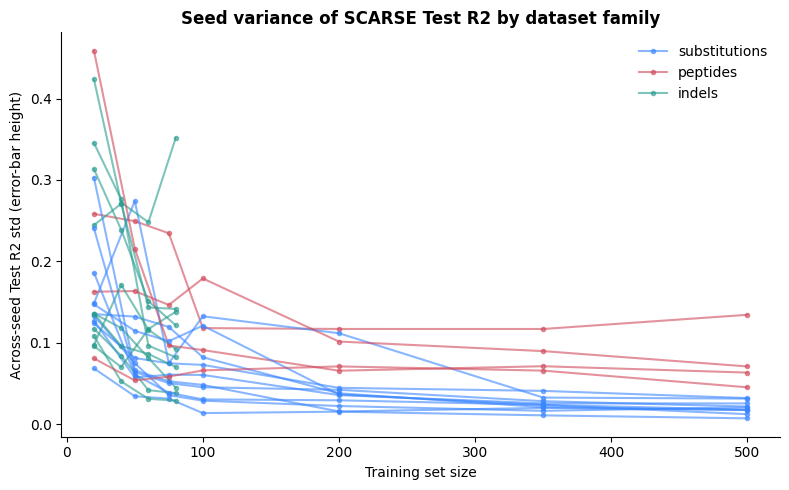

In [3]:
# Plot across-seed Test R2 std vs training size, coloured by dataset family.
if frames:
    fam_colour = {'peptides': '#d1495b', 'substitutions': '#3a86ff', 'indels': '#2a9d8f'}
    fig, ax = plt.subplots(figsize=(8, 5))
    for (ds, grp), g in scarse.groupby(['Dataset', 'group']):
        g = g.sort_values('Train Size')
        ax.plot(g['Train Size'], g['Test R2 Std'], 'o-', color=fam_colour.get(grp, '#999'),
                alpha=0.6, markersize=3, label=grp)
    # de-duplicate legend entries
    h, l = ax.get_legend_handles_labels()
    uniq = dict(zip(l, h)); ax.legend(uniq.values(), uniq.keys(), frameon=False)
    ax.set_xlabel('Training set size'); ax.set_ylabel('Across-seed Test R2 std (error-bar height)')
    ax.set_title('Seed variance of SCARSE Test R2 by dataset family', fontweight='bold')
    fig.tight_layout(); ac.savefig(fig, 'benchmark_seed_variance'); plt.show()


In [4]:
# Mean error-bar height at the smallest training size, AMP vs others.
if frames:
    smallest = scarse['Train Size'].min()
    at_small = scarse[scarse['Train Size'] == smallest].copy()
    at_small['is_amp'] = at_small['Dataset'].isin(ac.AMP_DATASETS)
    summary = at_small.groupby('is_amp')['Test R2 Std'].agg(['mean', 'median', 'max', 'count'])
    summary.index = ['AMP' if k else 'non-AMP' for k in summary.index]
    print(f'Across-seed Test R2 std at training size {smallest}:')
    print(summary.round(3).to_string())
    at_small[['Dataset','Test R2 Mean','Test R2 Std']].to_csv(
        os.path.join(ac.FIG_DIR, 'benchmark_seed_variance_smallest.csv'), index=False)
    print('\nIf AMP std is systematically higher, the Fig.2 AMP error bars reflect '
          'genuine sensitivity to the initial data draw, not evaluation noise.')


Across-seed Test R2 std at training size 20:
          mean  median    max  count
non-AMP  0.191   0.142  0.459     24

If AMP std is systematically higher, the Fig.2 AMP error bars reflect genuine sensitivity to the initial data draw, not evaluation noise.
